## Imports

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE, chi2
from sklearn.preprocessing import KBinsDiscretizer


X_train = pd.read_csv("../data/X_train_processed.csv")
X_test = pd.read_csv("../data/X_test_processed.csv")

y_train = pd.read_csv("../data/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/y_test.csv").squeeze("columns")

## Feature Importance

### Random Forest

In [ ]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

random_forest_importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

random_forest_importance_df

,feature,importance
17,thal_7.0,0.131646
5,thalach,0.116852
8,ca,0.105359
7,oldpeak,0.100880
11,cp_4.0,0.092969
0,age,0.090856
3,chol,0.081257
2,trestbps,0.080017
6,exang,0.052847
1,sex,0.037844


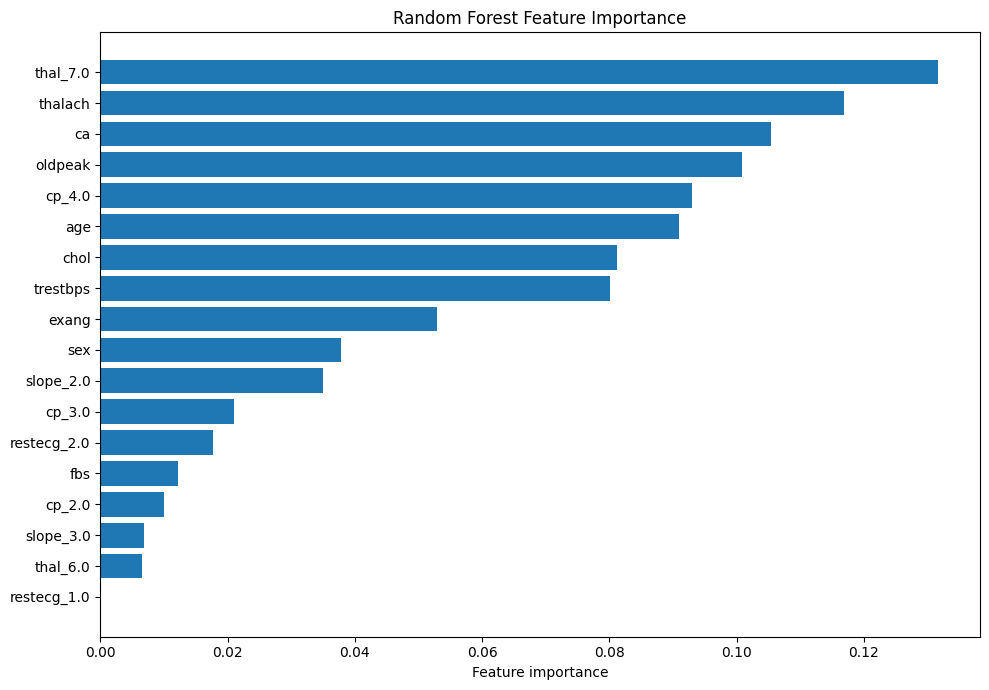

In [ ]:
plt.figure(figsize=(10, 7))

plt.barh(random_forest_importance_df["feature"],random_forest_importance_df["importance"])

plt.gca().invert_yaxis()
plt.xlabel("Feature importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig("../results/random_forest_feature_importance.png")
plt.show()

random_forest_importance_df.to_csv("../results/random_forest_feature_importance.csv", index=False)

### XGBoost

In [ ]:
xgb = XGBClassifier(n_estimators=200,random_state=42,eval_metric="logloss",importance_type="gain")
xgb.fit(X_train, y_train)

xgb_importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": xgb.feature_importances_
}).sort_values("importance", ascending=False)

xgb_importance_df

,feature,importance
17,thal_7.0,0.234658
11,cp_4.0,0.163572
8,ca,0.150050
1,sex,0.077982
9,cp_2.0,0.057897
14,slope_2.0,0.049305
0,age,0.041821
7,oldpeak,0.040711
2,trestbps,0.040175
6,exang,0.035386


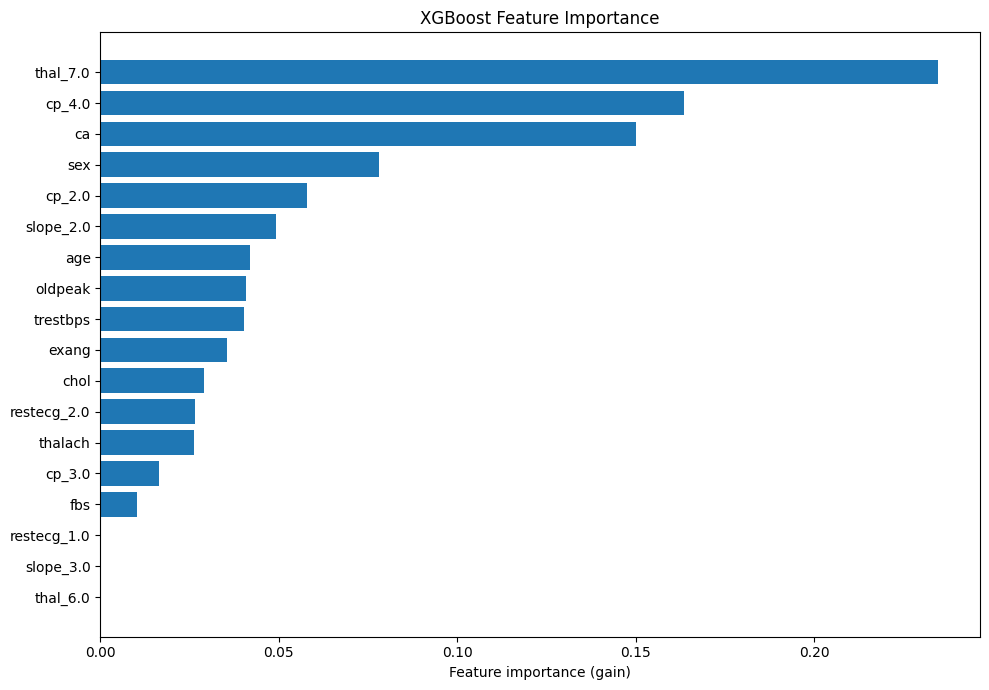

In [7]:
plt.figure(figsize=(10, 7))

plt.barh(
    xgb_importance_df["feature"],
    xgb_importance_df["importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Feature importance (gain)")
plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.savefig("../results/xgboost_feature_importance.png")
plt.show()

xgb_importance_df.to_csv(
    "../results/xgboost_feature_importance.csv", index=False
)

## Recursive Feature Elimination 

In [ ]:
rfe = RFE(estimator=LogisticRegression(max_iter=2000, random_state=42),n_features_to_select=8)

rfe.fit(X_train, y_train)

rfe_df = pd.DataFrame({
    "feature": X_train.columns,
    "rank": rfe.ranking_,
    "selected": rfe.support_
}).sort_values("rank")

rfe_df

,feature,rank,selected
1,sex,1,True
6,exang,1,True
9,cp_2.0,1,True
14,slope_2.0,1,True
13,restecg_2.0,1,True
11,cp_4.0,1,True
8,ca,1,True
17,thal_7.0,1,True
5,thalach,2,False
2,trestbps,3,False


In [9]:
rfe_df.to_csv("../results/rfe_ranking.csv", index=False)

In [14]:
rfe_selected = X_train.columns[rfe.support_].tolist()
rfe_selected

['sex',
 'exang',
 'ca',
 'cp_2.0',
 'cp_4.0',
 'restecg_2.0',
 'slope_2.0',
 'thal_7.0']

In [15]:
selected_variables = {col.split("_")[0] for col in rfe_selected}

selected_features = [
    col for col in X_train.columns
    if col.split("_")[0] in selected_variables
]

print("RFE-selected columns:", rfe_selected)
print("Selected original variables:", sorted(selected_variables))
print("Final columns:", selected_features)
print("Original column count:", X_train.shape[1])
print("Final column count:", len(selected_features))

RFE-selected columns: ['sex', 'exang', 'ca', 'cp_2.0', 'cp_4.0', 'restecg_2.0', 'slope_2.0', 'thal_7.0']
Selected original variables: ['ca', 'cp', 'exang', 'restecg', 'sex', 'slope', 'thal']
Final columns: ['sex', 'exang', 'ca', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_1.0', 'restecg_2.0', 'slope_2.0', 'slope_3.0', 'thal_6.0', 'thal_7.0']
Original column count: 18
Final column count: 12


## Chi-square Analysis

In [12]:
numerical_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

binner = KBinsDiscretizer(n_bins=3,encode="onehot-dense",strategy="quantile",subsample=None)
binned_data = binner.fit_transform(X_train[numerical_cols])

binned_df = pd.DataFrame(
    binned_data,
    columns=binner.get_feature_names_out(numerical_cols),
    index=X_train.index
)

X_chi = pd.concat([
    X_train.drop(columns=numerical_cols),
    binned_df
], axis=1)

scores, p_values = chi2(X_chi, y_train)

chi_df = pd.DataFrame({
    "feature_or_bin": X_chi.columns,
    "chi2_score": scores,
    "p_value": p_values,
    "significant": p_values < 0.05
}).sort_values("p_value")

chi_df

c:\Users\Malak Diab\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 5 are removed. Consider decreasing the number of bins.
  warnings.warn(


,feature_or_bin,chi2_score,p_value,significant
11,thal_7.0,39.245668,3.736966e-10,True
28,ca_1.0,30.967489,2.623870e-08,True
5,cp_4.0,29.621989,5.250591e-08,True
2,exang,28.791571,8.060112e-08,True
21,thalach_0.0,21.117332,4.320031e-06,True
27,ca_0.0,19.668540,9.210529e-06,True
23,thalach_2.0,16.461054,4.965977e-05,True
8,slope_2.0,15.455223,8.448314e-05,True
26,oldpeak_2.0,15.279540,9.271534e-05,True
3,cp_2.0,14.423951,1.459344e-04,True


In [13]:
chi_df.to_csv("../results/chi_square_results.csv", index=False)

## Save the Reduced Data

In [16]:
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

X_train_selected.to_csv("../data/X_train_selected.csv", index=False)
X_test_selected.to_csv("../data/X_test_selected.csv", index=False)

pd.DataFrame({
    "feature": selected_features
}).to_csv("../results/selected_features.csv", index=False)